=== 1. Mounting Google Drive ===
Mounted at /content/drive

📂 Project Base: /content/drive/MyDrive/VeritasNet
📂 Raw Directory: /content/drive/MyDrive/VeritasNet/data/raw

=== 2. Locating your Parquet File ===
📁 Files currently in data/raw/: ['mirage_news_raw.parquet']
✅ Found file: mirage_news_raw.parquet

=== 3. Loading Parquet Dataset ===
📊 Total Rows: 10000
📋 Columns: ['image', 'label', 'text']

📊 Missing Values Check:
image    0
label    0
text     0
dtype: int64

=== 4. First Row Data Inspection ===
🔹 image          : [Dictionary with keys ['bytes', 'path']]
🔹 label          : (int64) 1...
🔹 text           : (str) Andal Ampatuan Jr., a notorious crime lord in the southern Philippines, laughs off 41 murder charges...

=== 5. Label Distribution ===

Distribution of 'label':
label
1    5000
0    5000
Name: count, dtype: int64

=== 6. Testing Image Extraction ===
Targeting Image Column: 'image'
✅ Image decoded! Format: JPEG, Size: (600, 353), Mode: RGB


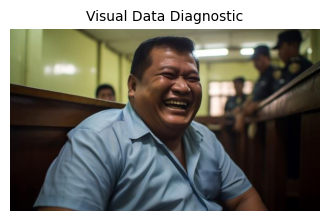

In [1]:
import os
import io
import pandas as pd
from PIL import Image
import matplotlib.pyplot as plt
from google.colab import drive

print("=== 1. Mounting Google Drive ===")
# Ensure Drive is mounted (checks both common mount points)
try:
    drive.mount('/content/drive', force_remount=True)
    DRIVE_PATH = "/content/drive/MyDrive"
except Exception as e:
    print("Fallback to alternative mount point...")
    drive.mount('/content/gdrive', force_remount=True)
    DRIVE_PATH = "/content/gdrive/MyDrive"

# 2. Re-establish VeritasNet structure paths
PROJECT_DIR = os.path.join(DRIVE_PATH, "VeritasNet")
RAW_DIR = os.path.join(PROJECT_DIR, "data/raw")

print(f"\n📂 Project Base: {PROJECT_DIR}")
print(f"📂 Raw Directory: {RAW_DIR}")

# Create directories if they don't exist
os.makedirs(RAW_DIR, exist_ok=True)

# 3. Locate your parquet file
print("\n=== 2. Locating your Parquet File ===")
files_in_raw = os.listdir(RAW_DIR)
print(f"📁 Files currently in data/raw/: {files_in_raw}")

matching_files = [f for f in files_in_raw if "mirage_news_raw" in f]

if not matching_files:
    print("\n⚠️ 'mirage_news_raw' file not detected in data/raw/.")
    print("👉 Please manually upload your parquet file to your Google Drive inside:")
    print(f"   My Drive > VeritasNet > data > raw")
    print("   And make sure its name contains 'mirage_news_raw'.")
else:
    filename = matching_files[0]
    parquet_path = os.path.join(RAW_DIR, filename)
    print(f"✅ Found file: {filename}")

    # 4. Loading and Verifying the Schema
    print("\n=== 3. Loading Parquet Dataset ===")
    try:
        df = pd.read_parquet(parquet_path)
        print(f"📊 Total Rows: {len(df)}")
        print(f"📋 Columns: {list(df.columns)}")

        # Check missing values
        print("\n📊 Missing Values Check:")
        print(df.isnull().sum())

        # Inspect first record
        print("\n=== 4. First Row Data Inspection ===")
        first_row = df.iloc[0]
        for col in df.columns:
            val = first_row[col]
            val_type = type(val)
            if isinstance(val, (bytes, bytearray)):
                print(f"🔹 {col:<15}: [Raw Bytes - length {len(val)}]")
            elif isinstance(val, dict):
                print(f"🔹 {col:<15}: [Dictionary with keys {list(val.keys())}]")
            else:
                print(f"🔹 {col:<15}: ({val_type.__name__}) {str(val)[:100]}...")

        # Target Label Verification
        print("\n=== 5. Label Distribution ===")
        label_cols = [c for c in df.columns if any(k in c.lower() for k in ['label', 'target', 'class', 'fake', 'real'])]
        if label_cols:
            for lc in label_cols:
                print(f"\nDistribution of '{lc}':")
                print(df[lc].value_counts())
        else:
            print("⚠️ No direct label/target column found. Columns are:", list(df.columns))

        # Image Decoding Test
        print("\n=== 6. Testing Image Extraction ===")
        image_cols = [c for c in df.columns if any(k in c.lower() for k in ['image', 'img', 'pic', 'photo'])]
        if image_cols:
            img_col = image_cols[0]
            print(f"Targeting Image Column: '{img_col}'")
            img_data = first_row[img_col]

            img = None
            if isinstance(img_data, dict) and 'bytes' in img_data:
                img = Image.open(io.BytesIO(img_data['bytes']))
            elif isinstance(img_data, (bytes, bytearray)):
                img = Image.open(io.BytesIO(img_data))
            elif isinstance(img_data, Image.Image):
                img = img_data

            if img:
                print(f"✅ Image decoded! Format: {img.format}, Size: {img.size}, Mode: {img.mode}")
                plt.figure(figsize=(4, 4))
                plt.imshow(img)
                plt.axis('off')
                plt.title("Visual Data Diagnostic", fontsize=10)
                plt.show()
            else:
                print(f"⚠️ Image column detected but could not be automatically decoded.")
        else:
            print("⚠️ No image column recognized.")

    except Exception as e:
        print(f"❌ Failed to process file: {e}")


In [3]:
# CELL 3: Comprehensive EDA, Preprocessing, Splitting & Leakage-Free Feature Extraction
import io
import re
import hashlib
import joblib
from PIL import Image
from torchvision import transforms
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer

PROCESSED_DIR = os.path.join(PROJECT_DIR, "data/processed")
MODELS_DIR = os.path.join(PROJECT_DIR, "models")
os.makedirs(PROCESSED_DIR, exist_ok=True)
os.makedirs(MODELS_DIR, exist_ok=True)

# 1. Dataset Inspection & Initial EDA
print("=== 1. Dataset Inspection & Initial EDA ===")
print(f"Initial Dataset Shape: {df.shape}")
df['char_len'] = df['text'].astype(str).str.len()
df['word_count'] = df['text'].astype(str).str.split().str.len()
print(f"Headline Word Count -> Mean: {df['word_count'].mean():.1f}, Min: {df['word_count'].min()}, Max: {df['word_count'].max()}")

# 2. Handling Missing Values & Duplicates (Text + Image Hash)
print("\n=== 2. Missing Values & Duplicate Removal ===")
initial_count = len(df)
df = df.dropna(subset=['image', 'text', 'label']).copy()

def get_img_hash(img_entry):
    if isinstance(img_entry, dict) and 'bytes' in img_entry and img_entry['bytes']:
        return hashlib.md5(img_entry['bytes']).hexdigest()
    return None

df['img_hash'] = df['image'].apply(get_img_hash)
df = df.dropna(subset=['img_hash'])

# Deduplicate on text and image-text pairs to prevent split leakage
df = df.drop_duplicates(subset=['text'], keep='first')
df = df.drop_duplicates(subset=['img_hash', 'text'], keep='first').reset_index(drop=True)
print(f"Rows before: {initial_count} | Rows after missing/duplicate removal: {len(df)} (Removed: {initial_count - len(df)})")

# 3. Text Cleaning & Tokenization Preparation
print("\n=== 3. Conservative Text Cleaning ===")
def clean_headline(text):
    text = str(text).lower()
    text = re.sub(r'http\S+|www\.\S+', '', text)       # Remove URLs
    text = re.sub(r'<.*?>', '', text)                  # Remove HTML
    text = re.sub(r'[^a-z0-9\s\'-]', ' ', text)        # Keep alphanumeric, apostrophes, hyphens
    text = re.sub(r'\s+', ' ', text).strip()           # Normalize spaces
    return text

df['cleaned_text'] = df['text'].apply(clean_headline)
df['tokens_preview'] = df['cleaned_text'].apply(lambda x: x.split()[:8])
df = df[df['cleaned_text'].str.len() > 3].reset_index(drop=True)
print(f"Sample Cleaned Text : {df['cleaned_text'].iloc[0][:80]}...")
print(f"Sample Tokens       : {df['tokens_preview'].iloc[0]}")

# 4. Image Decoding, Preprocessing & Text-Image Alignment Verification
print("\n=== 4. Image Decoding & Alignment Verification ===")
resnet_preprocess = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

valid_indices = []
for idx, row in df.iterrows():
    try:
        img_bytes = row['image']['bytes']
        with Image.open(io.BytesIO(img_bytes)) as img:
            img_rgb = img.convert("RGB")
            if idx == 0:
                sample_tensor = resnet_preprocess(img_rgb)
        if len(row['cleaned_text']) > 0:
            valid_indices.append(idx)
    except Exception:
        continue

df = df.loc[valid_indices].reset_index(drop=True)
print(f"✅ Aligned & Decodable Multimodal Records: {len(df)}")
print(f"✅ ResNet-18 Preprocessed Image Tensor Shape Verified: {tuple(sample_tensor.shape)}")

# 5. Label Encoding & Class Imbalance Analysis
print("\n=== 5. Label Encoding & Class Balance Analysis ===")
df['label'] = df['label'].astype(int)
class_counts = df['label'].value_counts().to_dict()
total_valid = len(df)
for cls, cnt in class_counts.items():
    print(f"Class {cls}: {cnt} samples ({(cnt/total_valid)*100:.2f}%)")

# 6. Reproducible Stratified Splitting & Leakage Prevention
print("\n=== 6. Stratified Splitting & Zero-Leakage Check ===")
train_df, temp_df = train_test_split(df, test_size=0.30, random_state=42, stratify=df['label'])
val_df, test_df = train_test_split(temp_df, test_size=0.50, random_state=42, stratify=temp_df['label'])

# Verify zero overlap of cleaned headlines across splits
assert len(set(train_df['cleaned_text']).intersection(set(val_df['cleaned_text']))) == 0
assert len(set(train_df['cleaned_text']).intersection(set(test_df['cleaned_text']))) == 0
print(f"✅ Split Sizes -> Train: {len(train_df)} | Val: {len(val_df)} | Test: {len(test_df)}")
print("✅ Leakage Prevention Verified: 0 overlapping headlines across Train/Val/Test.")

# 7. Model-Specific Text Feature Extraction (Fit ONLY on Train)
print("\n=== 7. TF-IDF Vectorization (Fit on Train Only) ===")
vectorizer = TfidfVectorizer(stop_words='english', max_features=5000, ngram_range=(1, 2))
X_train_tfidf = vectorizer.fit_transform(train_df['cleaned_text'])
X_val_tfidf = vectorizer.transform(val_df['cleaned_text'])
X_test_tfidf = vectorizer.transform(test_df['cleaned_text'])
print(f"✅ TF-IDF Shapes -> Train: {X_train_tfidf.shape}, Val: {X_val_tfidf.shape}, Test: {X_test_tfidf.shape}")

# 8. Data Validation & Saving to Google Drive
print("\n=== 8. Final Validation & Saving Processed Datasets ===")
cols_to_save_text = ['label', 'text', 'cleaned_text']
cols_to_save_full = ['image', 'label', 'text', 'cleaned_text', 'img_hash']

train_df[cols_to_save_text].to_csv(os.path.join(PROCESSED_DIR, "train_text.csv"), index=False)
val_df[cols_to_save_text].to_csv(os.path.join(PROCESSED_DIR, "val_text.csv"), index=False)
test_df[cols_to_save_text].to_csv(os.path.join(PROCESSED_DIR, "test_text.csv"), index=False)

train_df[cols_to_save_full].to_parquet(os.path.join(PROCESSED_DIR, "train_full.parquet"), index=False)
val_df[cols_to_save_full].to_parquet(os.path.join(PROCESSED_DIR, "val_full.parquet"), index=False)
test_df[cols_to_save_full].to_parquet(os.path.join(PROCESSED_DIR, "test_full.parquet"), index=False)

joblib.dump(vectorizer, os.path.join(MODELS_DIR, "tfidf_vectorizer.pkl"))
joblib.dump(resnet_preprocess, os.path.join(MODELS_DIR, "resnet_preprocess.pkl"))
print("💾 All processed datasets, TF-IDF vectorizer, and ResNet-18 transform pipeline saved and verified!")


=== 1. Dataset Inspection & Initial EDA ===
Initial Dataset Shape: (10000, 3)
Headline Word Count -> Mean: 20.1, Min: 4, Max: 83

=== 2. Missing Values & Duplicate Removal ===
Rows before: 10000 | Rows after missing/duplicate removal: 9997 (Removed: 3)

=== 3. Conservative Text Cleaning ===
Sample Cleaned Text : andal ampatuan jr a notorious crime lord in the southern philippines laughs off ...
Sample Tokens       : ['andal', 'ampatuan', 'jr', 'a', 'notorious', 'crime', 'lord', 'in']

=== 4. Image Decoding & Alignment Verification ===
✅ Aligned & Decodable Multimodal Records: 9997
✅ ResNet-18 Preprocessed Image Tensor Shape Verified: (3, 224, 224)

=== 5. Label Encoding & Class Balance Analysis ===
Class 1: 5000 samples (50.02%)
Class 0: 4997 samples (49.98%)

=== 6. Stratified Splitting & Zero-Leakage Check ===
✅ Split Sizes -> Train: 6997 | Val: 1500 | Test: 1500
✅ Leakage Prevention Verified: 0 overlapping headlines across Train/Val/Test.

=== 7. TF-IDF Vectorization (Fit on Train O

=== 1. Loading Processed Text Splits ===
Loaded Train: 6997 | Val: 1500 | Test: 1500
Loaded TF-IDF Vectorizer (Vocab size: 5000)

=== 2. Training Logistic Regression Baseline ===
✅ Baseline Model Trained successfully!

================ TRAIN SET PERFORMANCE ================
🎯 Accuracy: 0.8631

📝 Detailed Classification Report:
              precision    recall  f1-score   support

           0     0.8273    0.9176    0.8701      3497
           1     0.9076    0.8086    0.8552      3500

    accuracy                         0.8631      6997
   macro avg     0.8675    0.8631    0.8627      6997
weighted avg     0.8675    0.8631    0.8627      6997


================ VALIDATION SET PERFORMANCE ================
🎯 Accuracy: 0.7327

📝 Detailed Classification Report:
              precision    recall  f1-score   support

           0     0.7046    0.8013    0.7498       750
           1     0.7697    0.6640    0.7130       750

    accuracy                         0.7327      1500
   macro a

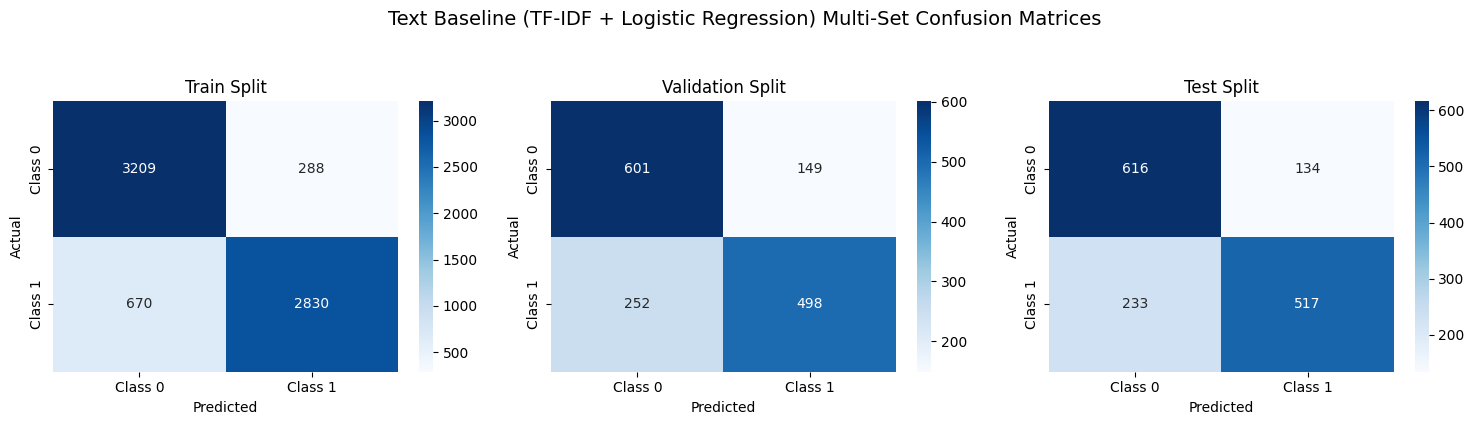

In [5]:
# CELL 4: Text-Only Baseline (TF-IDF + Logistic Regression) with Multi-Set Evaluation
import os
import joblib
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

# Define paths
PROCESSED_DIR = "/content/drive/MyDrive/VeritasNet/data/processed"
MODELS_DIR = "/content/drive/MyDrive/VeritasNet/models"
RESULTS_DIR = "/content/drive/MyDrive/VeritasNet/results"
os.makedirs(RESULTS_DIR, exist_ok=True)

print("=== 1. Loading Processed Text Splits ===")
train_df = pd.read_csv(os.path.join(PROCESSED_DIR, "train_text.csv"))
val_df = pd.read_csv(os.path.join(PROCESSED_DIR, "val_text.csv"))
test_df = pd.read_csv(os.path.join(PROCESSED_DIR, "test_text.csv"))

print(f"Loaded Train: {len(train_df)} | Val: {len(val_df)} | Test: {len(test_df)}")

# Load pre-fitted vectorizer
vectorizer_path = os.path.join(MODELS_DIR, "tfidf_vectorizer.pkl")
vectorizer = joblib.load(vectorizer_path)
print(f"Loaded TF-IDF Vectorizer (Vocab size: {len(vectorizer.vocabulary_)})")

# Transform text splits (Leakage-Free!)
X_train = vectorizer.transform(train_df['cleaned_text'])
X_val = vectorizer.transform(val_df['cleaned_text'])
X_test = vectorizer.transform(test_df['cleaned_text'])

y_train = train_df['label']
y_val = val_df['label']
y_test = test_df['label']

print("\n=== 2. Training Logistic Regression Baseline ===")
baseline_model = LogisticRegression(C=1.0, max_iter=1000, random_state=42)
baseline_model.fit(X_train, y_train)
print("✅ Baseline Model Trained successfully!")

# 3. Multi-Set Evaluation Function
def evaluate_split(X, y_true, split_name):
    y_pred = baseline_model.predict(X)
    acc = accuracy_score(y_true, y_pred)
    print(f"\n================ {split_name.upper()} SET PERFORMANCE ================")
    print(f"🎯 Accuracy: {acc:.4f}")
    print("\n📝 Detailed Classification Report:")
    print(classification_report(y_true, y_pred, digits=4))
    return y_pred, acc

# Run evaluations
y_pred_train, acc_train = evaluate_split(X_train, y_train, "Train")
y_pred_val, acc_val     = evaluate_split(X_val, y_val, "Validation")
y_pred_test, acc_test   = evaluate_split(X_test, y_test, "Test")

# Save baseline model
baseline_path = os.path.join(MODELS_DIR, "text_baseline_model.pkl")
joblib.dump(baseline_model, baseline_path)
print(f"\n💾 Saved baseline model to: {baseline_path}")

# 4. Save and Plot Confusion Matrices for All Splits
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
splits = [("Train", y_train, y_pred_train),
          ("Validation", y_val, y_pred_val),
          ("Test", y_test, y_pred_test)]

for i, (name, y_true, y_pred) in enumerate(splits):
    cm = confusion_matrix(y_true, y_pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[i],
                xticklabels=['Class 0', 'Class 1'],
                yticklabels=['Class 0', 'Class 1'])
    axes[i].set_title(f'{name} Split')
    axes[i].set_ylabel('Actual')
    axes[i].set_xlabel('Predicted')

plt.suptitle('Text Baseline (TF-IDF + Logistic Regression) Multi-Set Confusion Matrices', y=1.05, fontsize=14)
plt.tight_layout()
plt.savefig(os.path.join(RESULTS_DIR, "text_baseline_multi_set_confusion_matrix.png"), bbox_inches='tight')
plt.show()
